In [2]:
import pandas as pd
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score



from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

In [3]:
df = pd.read_csv(r'F:\Course AI online\AI\intro to deep lerning\train.csv')
df.head()

,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944468,57.862692,66.361592,36.116612,1.181795,1.062396,122.90607,31.794921,51.968828,...,2.257143,2.213364,2.219783,1.368922,1.066221,1,1.085714,0.433013,0.437059,29.0
1,5,92.729214,58.518416,73.132787,36.396602,1.449309,1.057755,122.90607,36.161939,47.094633,...,2.257143,1.888175,2.210679,1.557113,1.047221,2,1.128571,0.632456,0.468606,26.0
2,4,88.944468,57.885242,66.361592,36.122509,1.181795,0.975980,122.90607,35.741099,51.968828,...,2.271429,2.213364,2.232679,1.368922,1.029175,1,1.114286,0.433013,0.444697,19.0
3,4,88.944468,57.873967,66.361592,36.119560,1.181795,1.022291,122.90607,33.768010,51.968828,...,2.264286,2.213364,2.226222,1.368922,1.048834,1,1.100000,0.433013,0.440952,22.0
4,4,88.944468,57.840143,66.361592,36.110716,1.181795,1.129224,122.90607,27.848743,51.968828,...,2.242857,2.213364,2.206963,1.368922,1.096052,1,1.057143,0.433013,0.428809,23.0


In [4]:
scaler = StandardScaler()
scaler.fit(df)
df_scaled = scaler.transform(df)

In [5]:
df_scaled = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)
df_scaled.head()

,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,-0.080058,0.046733,-0.451651,-0.158850,-0.611819,0.044358,-0.003707,0.133725,-0.053039,0.378186,...,-0.752156,-0.805912,-0.711705,0.186292,0.035183,-0.837959,-0.406166,-0.838372,-0.520070,-0.158267
1,0.614744,0.174269,-0.432071,0.059368,-0.604180,0.777430,-0.015267,0.133725,0.108900,0.134901,...,-0.752156,-1.116731,-0.719454,0.664971,-0.014779,-0.033011,-0.362352,-0.426866,-0.450821,-0.245849
2,-0.080058,0.046733,-0.450978,-0.158850,-0.611658,0.044358,-0.218984,0.133725,0.093294,0.378186,...,-0.740164,-0.805912,-0.700728,0.186292,-0.062235,-0.837959,-0.376957,-0.838372,-0.503304,-0.450208
3,-0.080058,0.046733,-0.451314,-0.158850,-0.611739,0.044358,-0.103615,0.133725,0.020128,0.378186,...,-0.746160,-0.805912,-0.706224,0.186292,-0.010538,-0.837959,-0.391562,-0.838372,-0.511524,-0.362626
4,-0.080058,0.046733,-0.452324,-0.158850,-0.611980,0.044358,0.162775,0.133725,-0.199372,0.378186,...,-0.764149,-0.805912,-0.722618,0.186292,0.113627,-0.837959,-0.435376,-0.838372,-0.538178,-0.333432


## Data Cleaning 

In [6]:
df.isnull().sum()

number_of_elements       0
mean_atomic_mass         0
wtd_mean_atomic_mass     0
gmean_atomic_mass        0
wtd_gmean_atomic_mass    0
                        ..
range_Valence            0
wtd_range_Valence        0
std_Valence              0
wtd_std_Valence          0
critical_temp            0
Length: 82, dtype: int64

In [7]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
21258    False
21259    False
21260    False
21261    False
21262    False
Length: 21263, dtype: bool

## EDA (Expolatory Data Analysis)

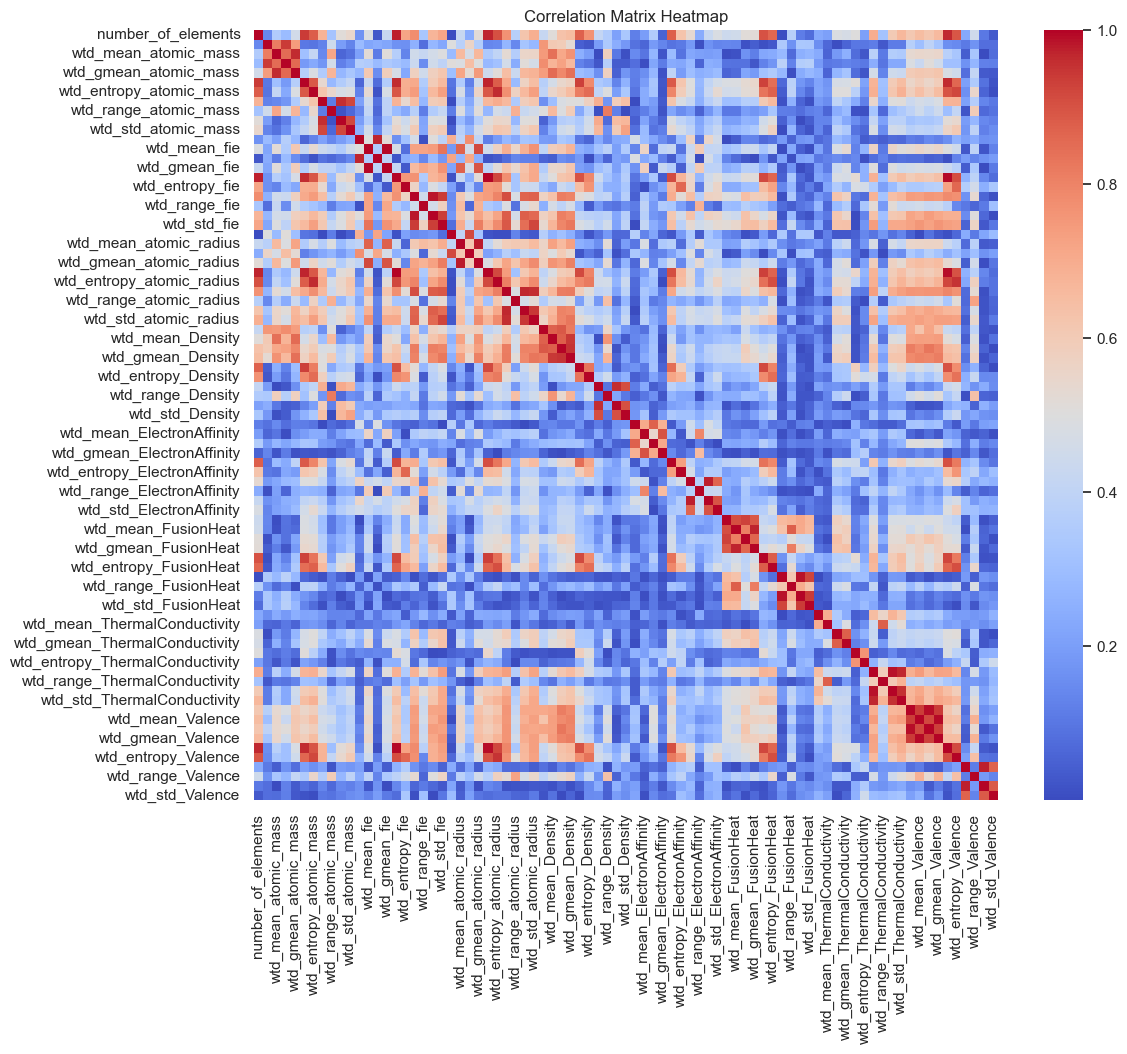

In [8]:
corr_matrix = df.drop(columns=['critical_temp']).corr().abs() ## critical_temp is  the target variable, so we drop it from the correlation matrix
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm',  fmt='.2f')
plt.title('Correlation Matrix Heatmap')
plt.show()


1. جاري رسم الـ Pairplot...


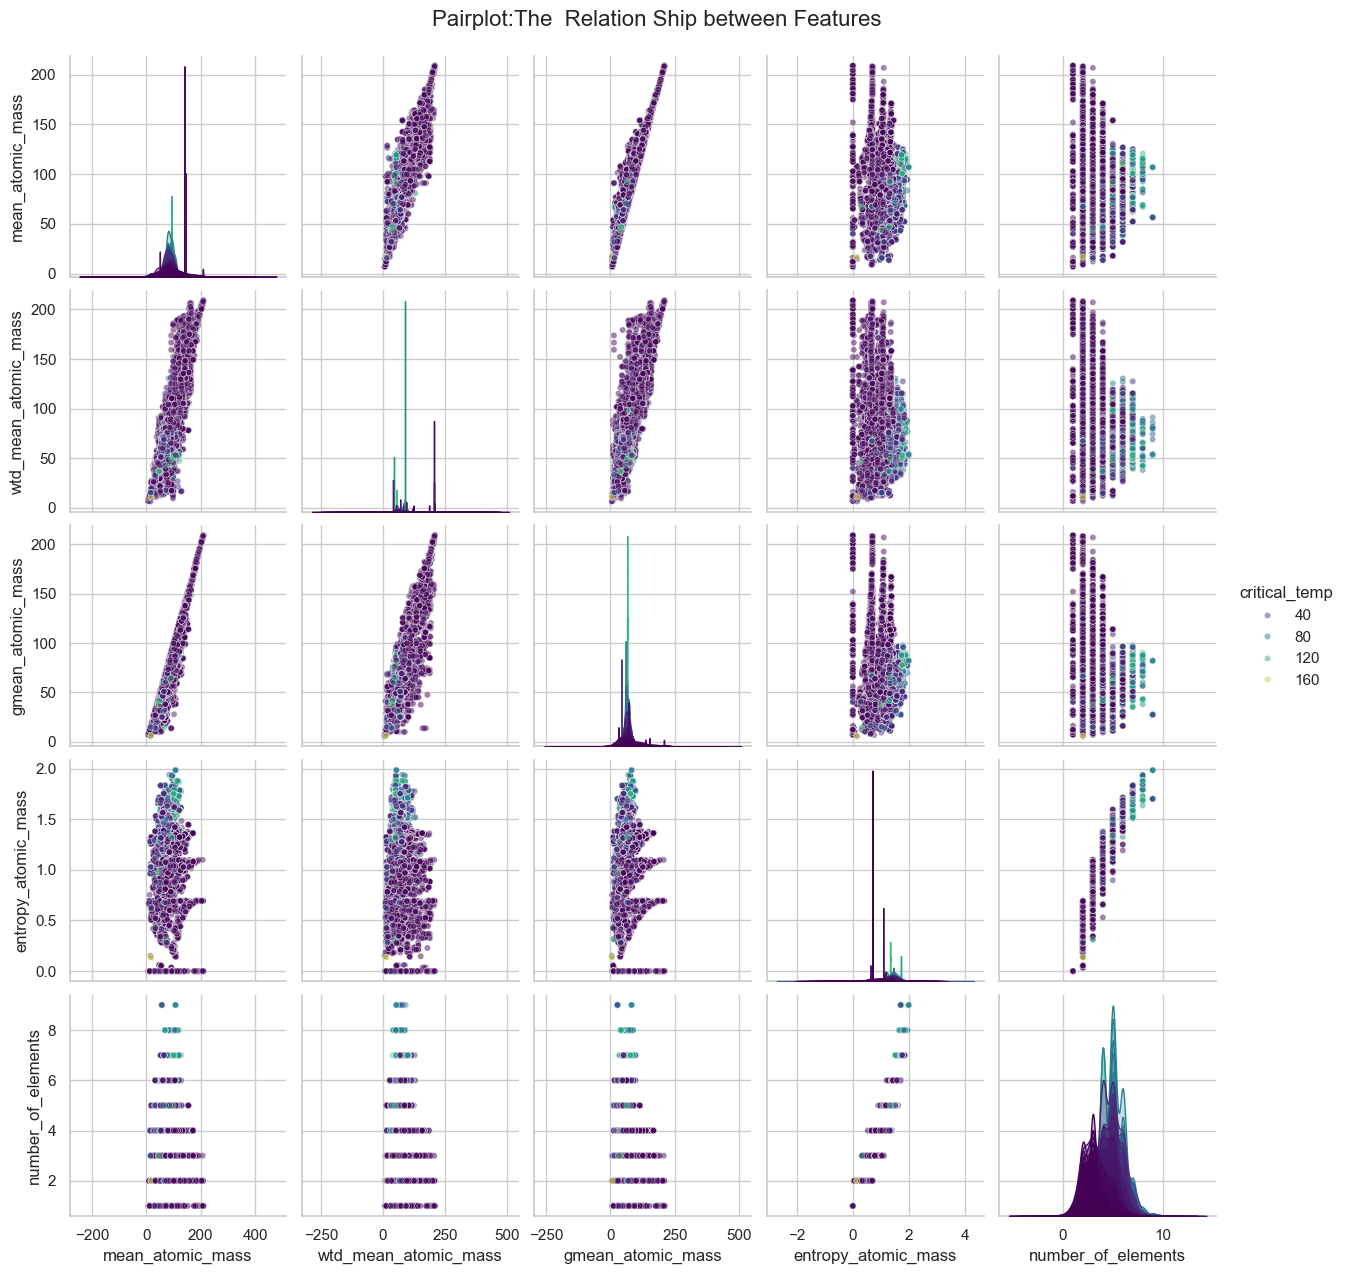

In [9]:
selected_features = [
    'mean_atomic_mass', 
    'wtd_mean_atomic_mass', 
    'gmean_atomic_mass', 
    'entropy_atomic_mass', 
    'number_of_elements'
]

print("1. جاري رسم الـ Pairplot...")

sns.pairplot(
    df[selected_features + ['critical_temp']],
    hue='critical_temp',          
    palette='viridis',      
    diag_kind='kde',         
    plot_kws={'alpha': 0.5, 's': 20}    
)
plt.suptitle('Pairplot:The  Relation Ship between Features   ', y=1.02, fontsize=16)
plt.show()

2. جاري رسم شبكة Scatter Plots...


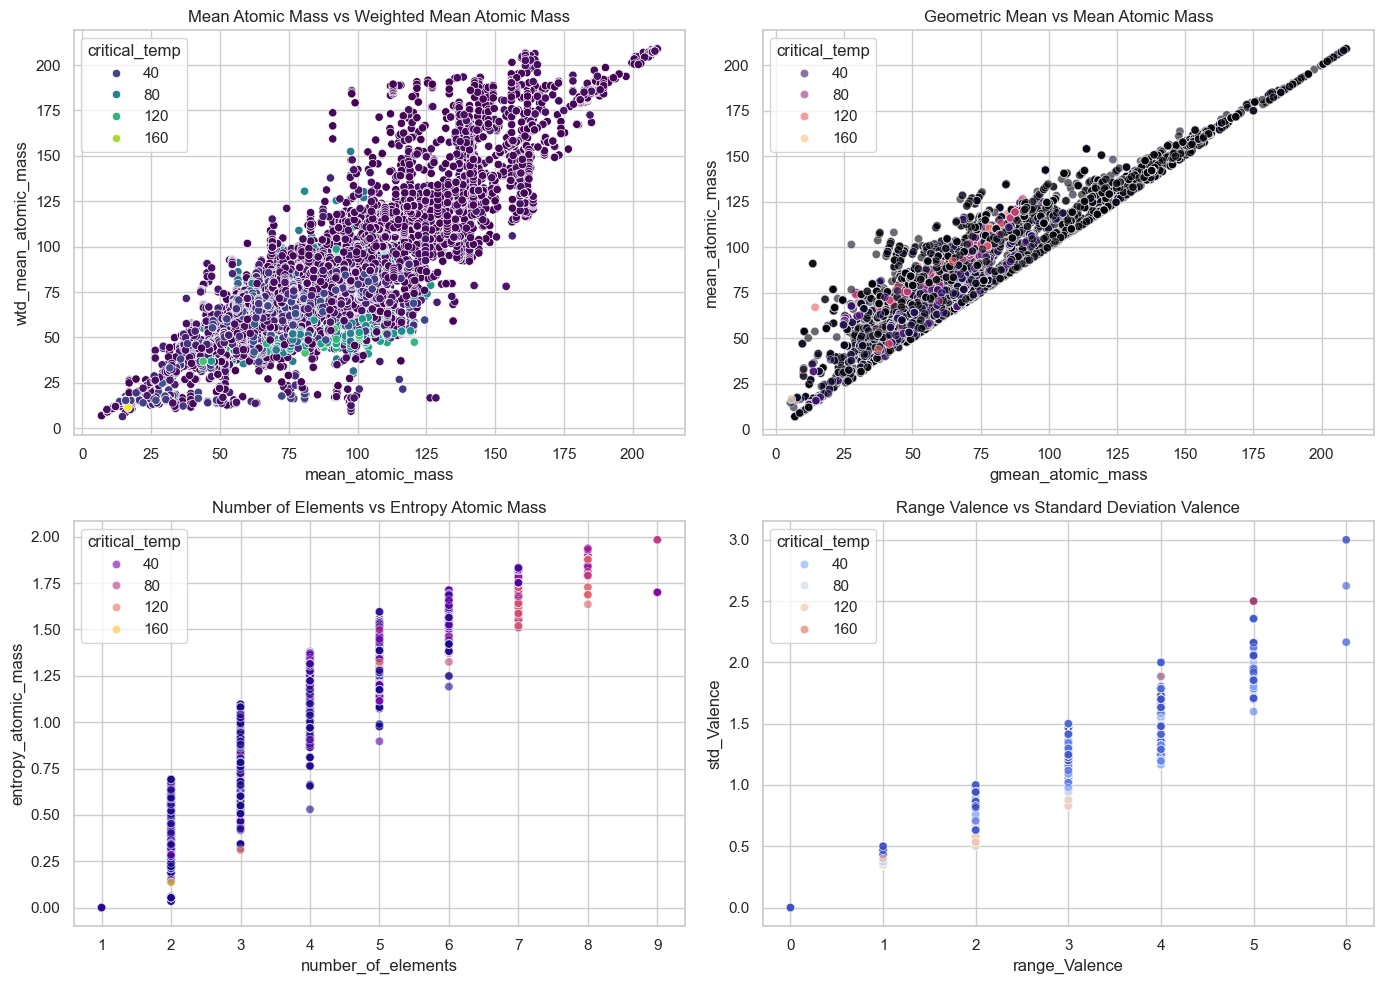

In [10]:
print("2. جاري رسم شبكة Scatter Plots...")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.scatterplot(
    data=df, x='mean_atomic_mass', y='wtd_mean_atomic_mass',
    hue='critical_temp', palette='viridis', alpha=1, ax=axes[0, 0]
)
axes[0, 0].set_title('Mean Atomic Mass vs Weighted Mean Atomic Mass', fontsize=12)




sns.scatterplot(
    data=df, x='gmean_atomic_mass', y='mean_atomic_mass',
    hue='critical_temp', palette='magma', alpha=0.6, ax=axes[0, 1]
)
axes[0, 1].set_title('Geometric Mean vs Mean Atomic Mass', fontsize=12)




sns.scatterplot(
    data=df, x='number_of_elements', y='entropy_atomic_mass',
    hue='critical_temp', palette='plasma', alpha=0.6, ax=axes[1, 0]
)
axes[1, 0].set_title('Number of Elements vs Entropy Atomic Mass', fontsize=12)




sns.scatterplot(
    data=df, x='range_Valence', y='std_Valence',
    hue='critical_temp', palette='coolwarm', alpha=0.6, ax=axes[1, 1]
)
axes[1, 1].set_title('Range Valence vs Standard Deviation Valence', fontsize=12)




plt.tight_layout()
plt.show()

3. جاري رسم الـ Jointplot...


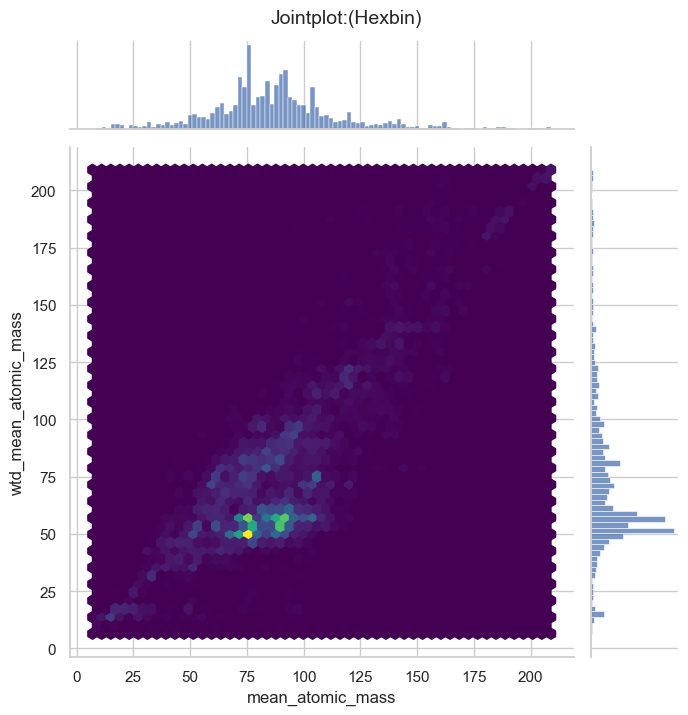

In [11]:
print("3. جاري رسم الـ Jointplot...")

g = sns.jointplot(
    data=df, 
    x='mean_atomic_mass', 
    y='wtd_mean_atomic_mass',
    kind='hex',
    cmap='viridis',
    height=7
)
g.fig.suptitle('Jointplot:(Hexbin)', y=1.02, fontsize=14)
plt.show()

4. جاري رسم الـ Regplot مع خط الاتجاه...


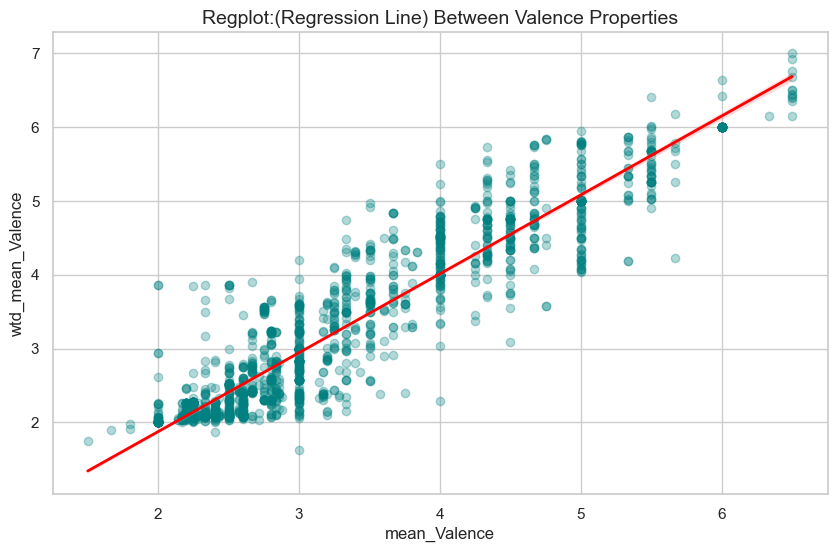

In [12]:

print("4. جاري رسم الـ Regplot مع خط الاتجاه...")

plt.figure(figsize=(10, 6))
sample_df = df.sample(n=2000, random_state=42)

sns.regplot(
    data=sample_df,
    x='mean_Valence',
    y='wtd_mean_Valence',
    scatter_kws={'alpha': 0.3, 'color': 'teal'},
    line_kws={'color': 'red', 'linewidth': 2}
)
plt.title('Regplot:(Regression Line) Between Valence Properties', fontsize=14)
plt.show()

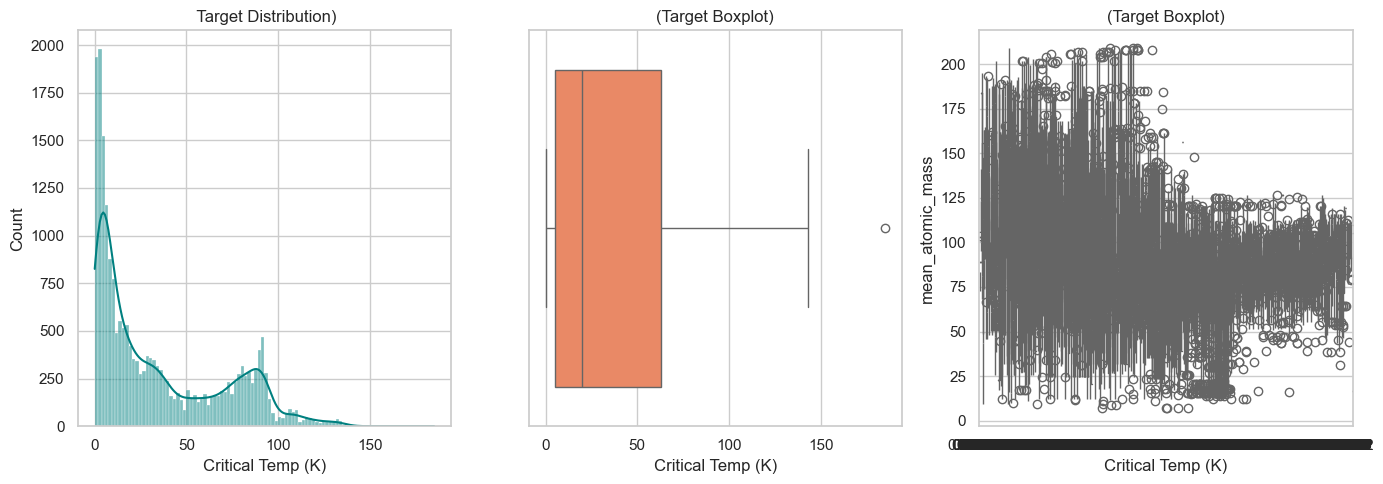

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

sns.histplot(df['critical_temp'], kde=True, bins=100, color='teal', ax=axes[0])
axes[0].set_title(' Target Distribution)', fontsize=12)
axes[0].set_xlabel('Critical Temp (K)')
axes[0].set_ylabel('Count')


sns.boxplot(x=df['critical_temp'], color='coral', ax=axes[1])
axes[1].set_title('(Target Boxplot)', fontsize=12)
axes[1].set_xlabel('Critical Temp (K)')



sns.boxplot(data=df,x='critical_temp',y='mean_atomic_mass', color='coral', ax=axes[2])
axes[2].set_title('(Target Boxplot)', fontsize=12)
axes[2].set_xlabel('Critical Temp (K)')

plt.tight_layout()
plt.show()

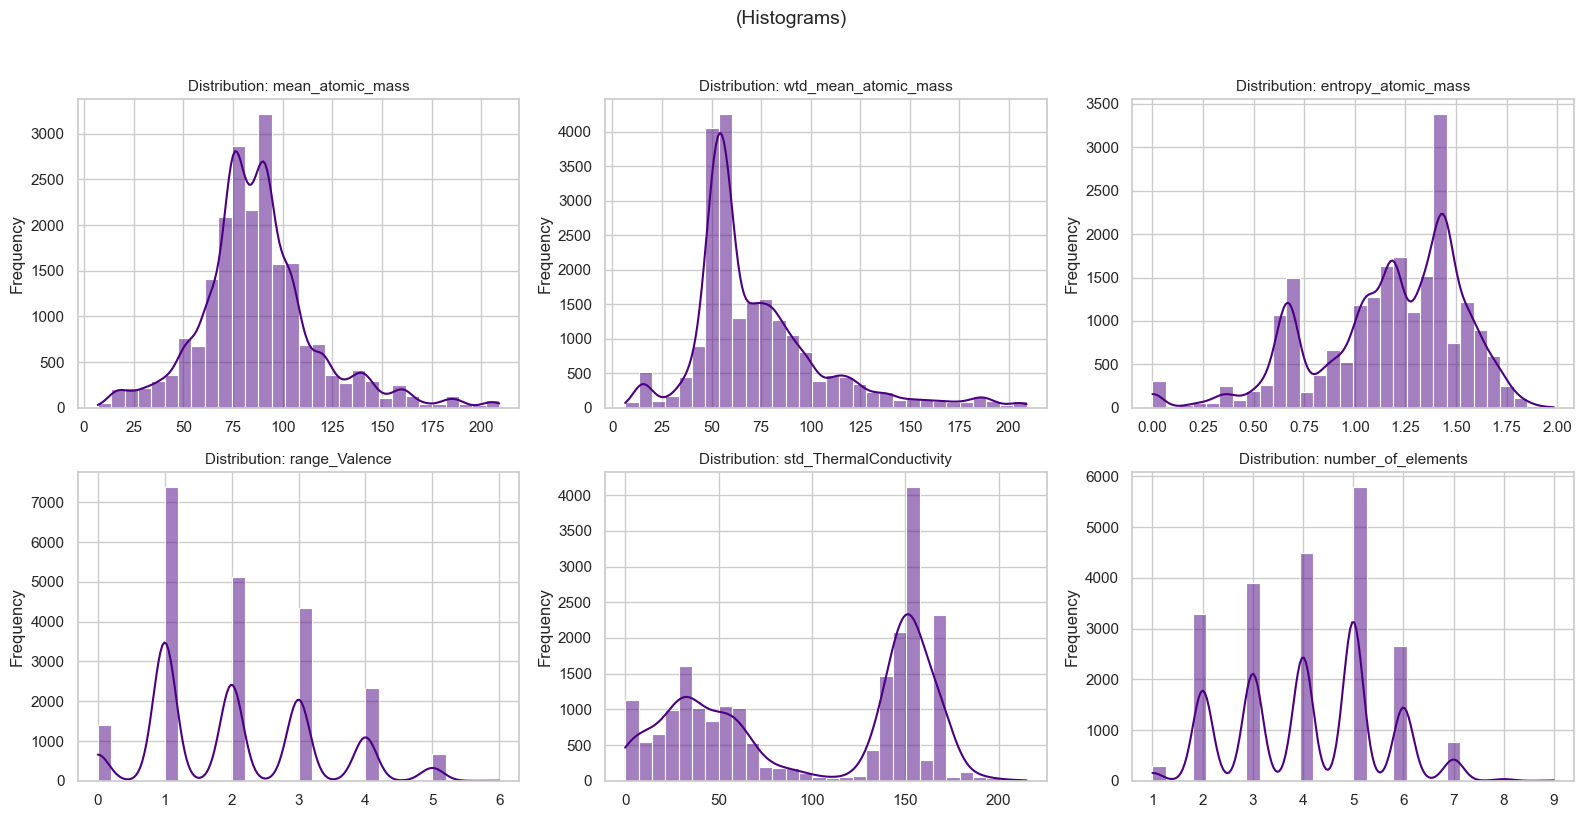

In [14]:
top_features = [
    'mean_atomic_mass', 
    'wtd_mean_atomic_mass', 
    'entropy_atomic_mass', 
    'range_Valence', 
    'std_ThermalConductivity',
    'number_of_elements'
]



fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(top_features):
    sns.histplot(df[col], kde=True, bins=30, color='indigo', ax=axes[i])
    axes[i].set_title(f'Distribution: {col}', fontsize=11)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frequency')


plt.suptitle('(Histograms)', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

## Histogram Uses in Numerical Data Analysis:

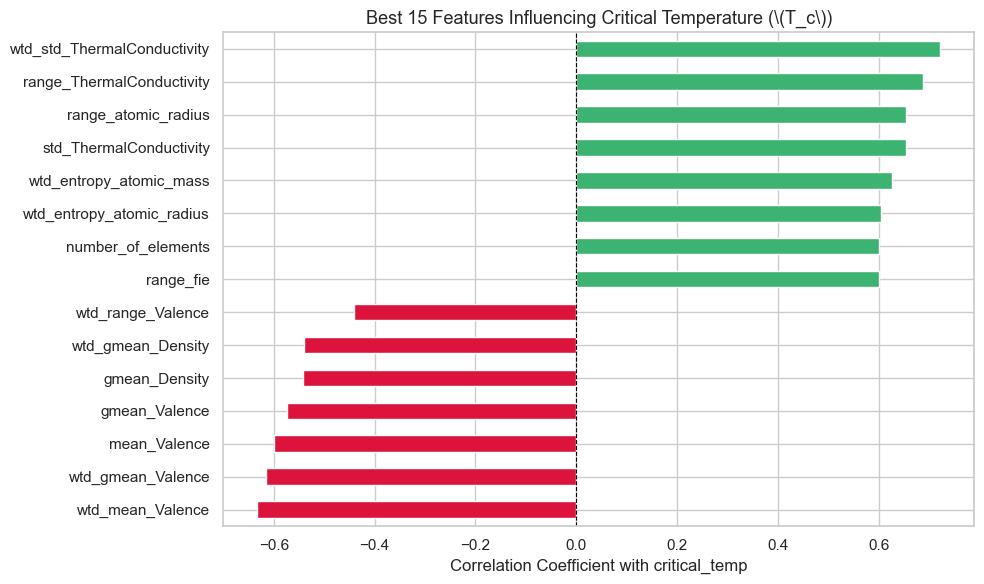

(Skewness)
(Log Transform)
wtd_mean_atomic_mass       1.503907
mean_atomic_mass           0.774681
range_Valence              0.469398
number_of_elements         0.009215
std_ThermalConductivity   -0.227791
entropy_atomic_mass       -0.785245
dtype: float64


In [20]:
target_corr = df.corr()['critical_temp'].drop('critical_temp').sort_values()

top_15_corr = pd.concat([target_corr.head(7), target_corr.tail(8)])

plt.figure(figsize=(10, 6))
colors = ['crimson' if val < 0 else 'mediumseagreen' for val in top_15_corr.values]
top_15_corr.plot(kind='barh', color=colors)

plt.title('Best 15 Features Influencing Critical Temperature (\\(T_c\\))', fontsize=13)
plt.xlabel('Correlation Coefficient with critical_temp')
plt.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()



skewness = df[top_features].skew().sort_values(ascending=False)
print("(Skewness)")
print("(Log Transform)")
print(skewness)

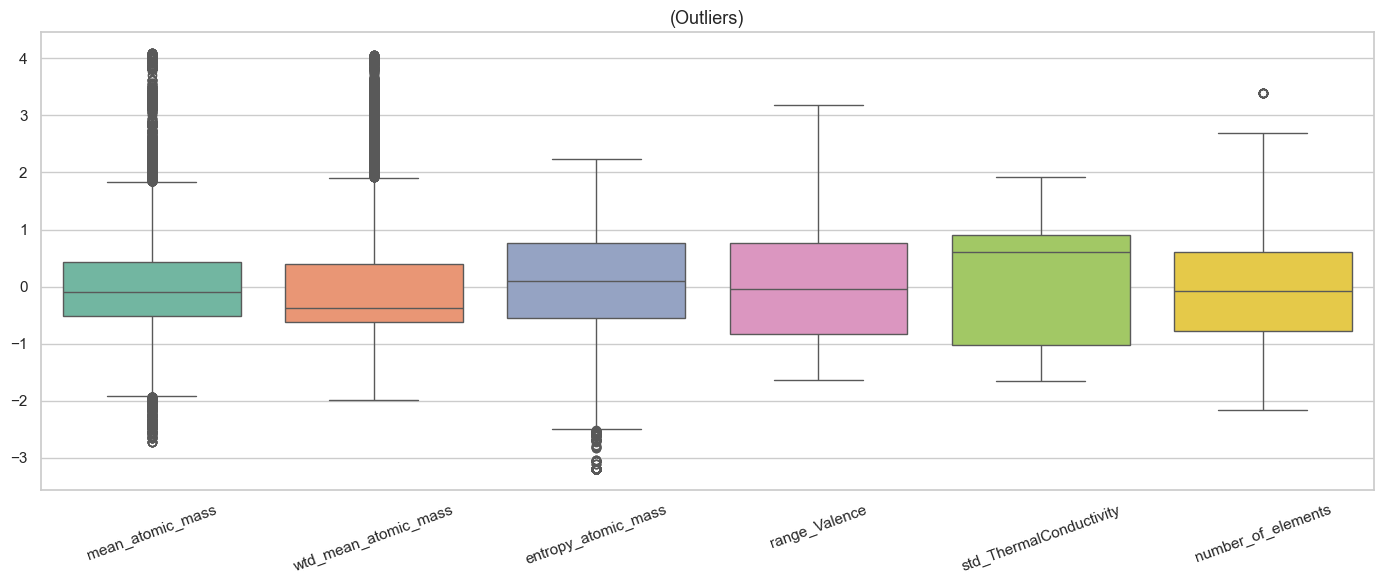

In [28]:
plt.figure(figsize=(14, 6))
from sklearn.preprocessing import StandardScaler
df_scaled_sample = pd.DataFrame(StandardScaler().fit_transform(df[top_features]), columns=top_features)

sns.boxplot(data=df_scaled_sample, palette='Set2')
plt.title('(Outliers)', fontsize=13)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [ ]:
skewness = df[top_features].skew().sort_values(ascending=False)
print("=== قيمة الانحراف (Skewness) للخصائص ===")
print("ملاحظة: القيم الأكبر من 1 أو أقل من -1 تعني أن التوزيع ملتوي ويحتاج التحويل (Log Transform)")
print(skewness)

=== قيمة الانحراف (Skewness) للخصائص ===
ملاحظة: القيم الأكبر من 1 أو أقل من -1 تعني أن التوزيع ملتوي ويحتاج التحويل (Log Transform)
wtd_mean_atomic_mass       1.503907
mean_atomic_mass           0.774681
range_Valence              0.469398
number_of_elements         0.009215
std_ThermalConductivity   -0.227791
entropy_atomic_mass       -0.785245
dtype: float64


In [27]:
X = df.drop(columns=['critical_temp'])
y = df['critical_temp'].values.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42,shuffle=True
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

X_train = scaler.fit_transform(X_train)
X_test= scaler.transform(X_test)

y_train = scaler.fit_transform(y_train)
y_test = scaler.transform(y_test)


(14246, 81)
(7017, 81)
(14246, 1)
(7017, 1)


In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)

test_dataset = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32)
)

BATCH_SIZE = 64

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("الـ DataLoaders جاهزة تماماً!")

الـ DataLoaders جاهزة تماماً!


In [ ]:
import torch.nn as nn
import torch.optim as optim

# تعريف معمارية الشبكة
class SuperconductorNN(nn.Module):
    def __init__(self, input_dim):
        super(SuperconductorNN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),
            
            nn.Linear(64, 32),
            nn.ReLU(),
            
            nn.Linear(32, 1) # مخرج واحد للتنبؤ بـ critical_temp
        )

    def forward(self, x):
        return self.net(x)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

input_dim = X_train.shape[1]
model = SuperconductorNN(input_dim=input_dim).to(device)

print(model)

SuperconductorNN(
  (net): Sequential(
    (0): Linear(in_features=81, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): ReLU()
    (10): Linear(in_features=32, out_features=1, bias=True)
  )
)
